In [220]:
import pandas as pd
df = pd.read_csv('/Users/augustw/code/alessandra-gentile/XY_Coordinates_v3.csv')

In [221]:
df_spots = pd.read_csv('/Users/augustw/code/alessandra-gentile/PBS 3-MaxIP_segmented_spots.csv', skiprows=[1, 2, 3])
df_spots.head()

,Label,Spot ID,Track ID,Quality,X,Y,Z,T,Frame,Radius,...,Ellipse center y0,Ellipse long axis,Ellipse short axis,Ellipse angle,Ellipse aspect ratio,Area,Perimeter,Circularity,Solidity,Shape index
0,ID142978,142978,1,471,576.603499,503.555788,0,63878.476440,53,10.501093,...,-0.009014,12.192390,9.202367,1.526482,1.324919,346.432710,74.053735,0.793843,0.942289,3.978666
1,ID141059,141059,1,455,576.348688,504.868640,0,49415.425171,41,10.259914,...,-0.050678,12.090523,8.912077,1.102137,1.356645,330.702397,83.140148,0.601209,0.908543,4.571852
2,ID141955,141955,1,363,577.362216,504.690650,0,55441.696533,46,9.200824,...,-0.040882,9.876029,9.049855,0.894591,1.091291,265.952038,63.137399,0.838378,0.975839,3.871551
3,ID143495,143495,1,542,577.230069,500.026576,0,72315.256348,60,11.240209,...,0.038331,12.842567,10.004736,1.608815,1.283649,396.916041,91.016465,0.602100,0.907191,4.568469
4,ID138757,138757,1,526,575.399692,507.203310,0,14463.051270,12,11.120435,...,0.083976,11.883069,10.389727,-1.076462,1.143733,388.502152,95.780848,0.532165,0.879139,4.859392


In [222]:
df_tracks = pd.read_csv('/Users/augustw/code/alessandra-gentile/PBS 3-MaxIP_segmented_tracks.csv', skiprows=[1, 2, 3])
df_tracks.head()


,Label,Track index,Track ID,Number of spots in track,Number of gaps,Number of split events,Number of merge events,Number of complex points,Longest gap,Track duration,...,Track min speed,Track median speed,Track std speed,Track mean quality,Total distance traveled,Max distance traveled,Confinement ratio,Mean straight line speed,Linearity of forward progression,Mean directional change rate
0,Track_729,4,4,34,0,0,0,0,0,39773.39099,...,0.000127,0.001127,0.000828,537.264706,54.221808,15.497989,0.188878,0.000257,0.188878,0.001631
1,Track_730,5,5,29,0,0,0,0,0,33747.11963,...,0.000055,0.000929,0.000627,537.655172,32.311617,11.537138,0.356617,0.000341,0.356617,0.001463
2,Track_731,6,6,96,0,0,0,0,0,114499.15590,...,0.000112,0.001364,0.001221,752.739583,177.406499,27.662938,0.129255,0.000200,0.129255,0.001633
3,Track_732,7,7,20,0,0,0,0,0,22899.83118,...,0.000130,0.000731,0.004900,515.600000,45.328049,27.925776,0.616082,0.001219,0.616082,0.001340
4,Track_733,8,8,105,1,0,0,0,1,126551.69860,...,0.000158,0.001167,0.004677,805.104762,318.086674,41.200894,0.084178,0.000212,0.083608,0.001442


In [223]:
import numpy as np

curve = df[['X', 'Y']].dropna().to_numpy(dtype=float)

if len(curve) < 2:
    raise ValueError('The boundary polyline needs at least two points.')


### Clean the boundary polyline

The boundary is treated as an ordered polyline. Before using it, we remove consecutive duplicate points so that zero-length segments do not create divide-by-zero problems later.


In [224]:
# Remove consecutive duplicates so each segment has a non-zero length.
segment_steps = np.linalg.norm(np.diff(curve, axis=0), axis=1)
curve = curve[np.r_[True, segment_steps > 0]]

if len(curve) < 2:
    raise ValueError('The boundary polyline collapses to fewer than two unique points.')


### Compute arc length along the boundary

These cumulative distances give each location on the polyline a tangential coordinate. Later, the closest point on the boundary will be reported both by its XY location and by its arc-length position.


In [225]:
segment_vectors = np.diff(curve, axis=0)
segment_lengths = np.linalg.norm(segment_vectors, axis=1)
arc_lengths = np.concatenate([[0.0], np.cumsum(segment_lengths)])


### Helper: project one point onto one line segment

For a point `p` and a segment from `a` to `b`, this helper finds the closest point on that segment and returns both the projected XY position and the segment fraction `t`.


In [226]:
def point_to_segment(p, a, b):
    ab = b - a
    ab2 = np.dot(ab, ab)
    if ab2 == 0:
        return a.copy(), 0.0

    t = np.dot(p - a, ab) / ab2
    t = np.clip(t, 0.0, 1.0)
    closest = a + t * ab
    return closest, t


### Helper: signed distance from a point to the whole boundary

This function checks every segment in the polyline, keeps the closest projection, and then assigns a sign using the local segment normal. It returns four things: signed distance, closest XY point, segment index, and arc-length position along the boundary.


In [227]:
def signed_distance_to_polyline(p, curve, arc_lengths):
    best_dist2 = np.inf
    best_closest = None
    best_segment_index = None
    best_t = None

    for i in range(len(curve) - 1):
        a, b = curve[i], curve[i + 1]
        closest, t = point_to_segment(p, a, b)
        diff = p - closest
        dist2 = np.dot(diff, diff)

        if dist2 < best_dist2:
            best_dist2 = dist2
            best_closest = closest
            best_segment_index = i
            best_t = t

    a = curve[best_segment_index]
    b = curve[best_segment_index + 1]
    tangent = b - a
    tangent = tangent / np.linalg.norm(tangent)
    normal = np.array([-tangent[1], tangent[0]])

    offset = p - best_closest
    dot = np.dot(offset, normal)
    sign = -1.0 if dot > 0 else 1.0 if dot < 0 else 0.0

    signed_distance = sign * np.sqrt(best_dist2)
    s = arc_lengths[best_segment_index] + best_t * np.linalg.norm(b - a)

    return signed_distance, best_closest, best_segment_index, s


In [228]:
spot_xy = df_spots.iloc[:, [4, 5]].to_numpy(dtype=float)

results = np.array([
    signed_distance_to_polyline(p, curve, arc_lengths)
    for p in spot_xy
], dtype=object)

df_spots['signed_distance_to_boundary'] = results[:, 0].astype(float)
df_spots['closest_boundary_x'] = np.vstack(results[:, 1])[:, 0]
df_spots['closest_boundary_y'] = np.vstack(results[:, 1])[:, 1]
df_spots['closest_boundary_segment'] = results[:, 2].astype(int)
df_spots['boundary_arc_length'] = results[:, 3].astype(float)

# If the sign is flipped relative to your biological convention, reverse `curve`
# or multiply `signed_distance_to_boundary` by -1 after inspecting a few points.
df_spots[['X', 'Y', 'signed_distance_to_boundary', 'boundary_arc_length']]


,X,Y,signed_distance_to_boundary,boundary_arc_length
0,576.603499,503.555788,162.103349,499.53691
1,576.348688,504.868640,160.772937,499.53691
2,577.362216,504.690650,161.043738,499.53691
3,577.230069,500.026576,165.674940,499.53691
4,575.399692,507.203310,158.364602,499.53691
...,...,...,...,...
8818,617.368314,202.238248,466.062324,499.53691
8819,622.336478,241.021993,428.249742,499.53691
8820,618.086416,198.427351,469.931615,499.53691
8821,618.835699,197.908848,470.536334,499.53691


### Compute radial speed for each track link

For each `Track ID`, we sort spots by time `T` and compare each spot to the next one in the same track. The radial speed is the change in signed distance divided by the elapsed time, so for this dataset it is reported in microns per second.


In [229]:
track_links = df_spots[['Track ID', 'Spot ID', 'T', 'Frame', 'X', 'Y', 'signed_distance_to_boundary']].copy()
track_links = track_links.sort_values(['Track ID', 'T', 'Spot ID']).reset_index(drop=True)

same_track_as_next = track_links['Track ID'] == track_links['Track ID'].shift(-1)

track_links['next_spot_id'] = track_links['Spot ID'].shift(-1)
track_links['next_t'] = track_links['T'].shift(-1)
track_links['next_frame'] = track_links['Frame'].shift(-1)
track_links['next_x'] = track_links['X'].shift(-1)
track_links['next_y'] = track_links['Y'].shift(-1)
track_links['next_signed_distance'] = track_links['signed_distance_to_boundary'].shift(-1)

track_links['delta_t_s'] = track_links['next_t'] - track_links['T']
track_links['delta_x_um'] = track_links['next_x'] - track_links['X']
track_links['delta_y_um'] = track_links['next_y'] - track_links['Y']
track_links['delta_signed_distance_um'] = track_links['next_signed_distance'] - track_links['signed_distance_to_boundary']

track_links = track_links[same_track_as_next].copy()
track_links = track_links[track_links['delta_t_s'] != 0].copy()

track_links['radial_speed_um_per_s'] = track_links['delta_signed_distance_um'] / track_links['delta_t_s']

track_links.head()


,Track ID,Spot ID,T,Frame,X,Y,signed_distance_to_boundary,next_spot_id,next_t,next_frame,next_x,next_y,next_signed_distance,delta_t_s,delta_x_um,delta_y_um,delta_signed_distance_um,radial_speed_um_per_s
0,1,138084,0.000000,0,571.989264,509.484126,155.836364,137968.0,1205.254272,1.0,571.860753,508.052632,157.256831,1205.254272,-0.128511,-1.431495,1.420467,0.001179
1,1,137968,1205.254272,1,571.860753,508.052632,157.256831,138394.0,2410.508545,2.0,573.127727,506.318723,159.070971,1205.254272,1.266974,-1.733908,1.814140,0.001505
2,1,138394,2410.508545,2,573.127727,506.318723,159.070971,137923.0,3615.762817,3.0,573.825386,504.357440,161.077224,1205.254272,0.697658,-1.961284,2.006252,0.001665
3,1,137923,3615.762817,3,573.825386,504.357440,161.077224,138192.0,4821.017090,4.0,574.169603,504.547135,160.913707,1205.254273,0.344217,0.189695,-0.163516,-0.000136
4,1,138192,4821.017090,4,574.169603,504.547135,160.913707,138337.0,6026.271362,5.0,574.427287,504.791463,160.689803,1205.254272,0.257684,0.244328,-0.223904,-0.000186


### Summarize radial speed at the track level

This table collapses the link-level radial speeds into one row per track, giving the mean, maximum, median, and standard deviation of radial speed for each `Track ID`.


In [230]:
track_speed_summary = (
    track_links.groupby('Track ID')['radial_speed_um_per_s']
    .agg(['mean', 'max', 'median', 'std'])
    .rename(columns={
        'mean': 'mean_radial_speed_um_per_s',
        'max': 'max_radial_speed_um_per_s',
        'median': 'median_radial_speed_um_per_s',
        'std': 'std_radial_speed_um_per_s',
    })
    .reset_index()
)

track_speed_summary.head()


,Track ID,mean_radial_speed_um_per_s,max_radial_speed_um_per_s,median_radial_speed_um_per_s,std_radial_speed_um_per_s
0,1,0.000077,0.001752,0.000052,0.000903
1,3,-0.000109,0.001866,-0.000036,0.000940
2,4,0.000220,0.002690,0.000240,0.001267
3,5,0.000154,0.001520,0.000241,0.000974
4,6,0.000144,0.004717,0.000136,0.001127


### Derive tangential speed from total and radial link motion

Each link has a total XY displacement and a radial displacement relative to the boundary. We use these to compute the tangential speed magnitude for each link using `total^2 = radial^2 + tangential^2`.


In [231]:
track_links['link_speed_um_per_s'] = np.sqrt(
    track_links['delta_x_um'] ** 2 + track_links['delta_y_um'] ** 2
) / track_links['delta_t_s']

track_links['tangential_speed_um_per_s'] = np.sqrt(np.clip(
    track_links['link_speed_um_per_s'] ** 2 - track_links['radial_speed_um_per_s'] ** 2,
    a_min=0,
    a_max=None,
))

track_links[['Track ID', 'Spot ID', 'next_spot_id', 'link_speed_um_per_s', 'radial_speed_um_per_s', 'tangential_speed_um_per_s']].head()


,Track ID,Spot ID,next_spot_id,link_speed_um_per_s,radial_speed_um_per_s,tangential_speed_um_per_s
0,1,138084,137968.0,0.001192,0.001179,0.000182
1,1,137968,138394.0,0.001782,0.001505,0.000953
2,1,138394,137923.0,0.001727,0.001665,0.000461
3,1,137923,138192.0,0.000326,-0.000136,0.000297
4,1,138192,138337.0,0.000295,-0.000186,0.000229


### Recompute track speed statistics from link speeds

This step validates the speed summary stored in `df_tracks` by recalculating mean, maximum, median, and standard deviation of speed directly from the per-link XY speeds.


In [232]:
track_speed_validation = (
    track_links.groupby('Track ID')['link_speed_um_per_s']
    .agg(['mean', 'max', 'median', 'std'])
    .rename(columns={
        'mean': 'recomputed_mean_speed_um_per_s',
        'max': 'recomputed_max_speed_um_per_s',
        'median': 'recomputed_median_speed_um_per_s',
        'std': 'recomputed_std_speed_um_per_s',
    })
    .reset_index()
)

track_speed_validation.head()


,Track ID,recomputed_mean_speed_um_per_s,recomputed_max_speed_um_per_s,recomputed_median_speed_um_per_s,recomputed_std_speed_um_per_s
0,1,0.001004,0.002850,0.000984,0.000591
1,3,0.001063,0.004313,0.001057,0.000690
2,4,0.001363,0.003589,0.001127,0.000828
3,5,0.000957,0.002861,0.000882,0.000627
4,6,0.001549,0.007868,0.001364,0.001221


In [233]:
track_speed_validation_comparison = (
    df_tracks[[
        'Track ID',
        'Track mean speed',
        'Track max speed',
        'Track median speed',
        'Track std speed',
    ]]
    .merge(track_speed_validation, on='Track ID', how='inner')
    .rename(columns={
        'Track mean speed': 'reported_mean_speed_um_per_s',
        'Track max speed': 'reported_max_speed_um_per_s',
        'Track median speed': 'reported_median_speed_um_per_s',
        'Track std speed': 'reported_std_speed_um_per_s',
    })
)

track_speed_validation_comparison['mean_speed_difference'] = (
    track_speed_validation_comparison['recomputed_mean_speed_um_per_s']
    - track_speed_validation_comparison['reported_mean_speed_um_per_s']
)
track_speed_validation_comparison['max_speed_difference'] = (
    track_speed_validation_comparison['recomputed_max_speed_um_per_s']
    - track_speed_validation_comparison['reported_max_speed_um_per_s']
)
track_speed_validation_comparison['median_speed_difference'] = (
    track_speed_validation_comparison['recomputed_median_speed_um_per_s']
    - track_speed_validation_comparison['reported_median_speed_um_per_s']
)
track_speed_validation_comparison['std_speed_difference'] = (
    track_speed_validation_comparison['recomputed_std_speed_um_per_s']
    - track_speed_validation_comparison['reported_std_speed_um_per_s']
)

track_speed_validation_comparison.head()


,Track ID,reported_mean_speed_um_per_s,reported_max_speed_um_per_s,reported_median_speed_um_per_s,reported_std_speed_um_per_s,recomputed_mean_speed_um_per_s,recomputed_max_speed_um_per_s,recomputed_median_speed_um_per_s,recomputed_std_speed_um_per_s,mean_speed_difference,max_speed_difference,median_speed_difference,std_speed_difference
0,4,0.001363,0.003589,0.001127,0.000828,0.001363,0.003589,0.001127,0.000828,4.301711e-10,1.471140e-10,2.423938e-10,4.974596e-07
1,5,0.000957,0.002861,0.000929,0.000627,0.000957,0.002861,0.000882,0.000627,4.629493e-07,-3.645747e-11,-4.670311e-05,1.850170e-07
2,6,0.001549,0.007868,0.001364,0.001221,0.001549,0.007868,0.001364,0.001221,1.619776e-10,4.297856e-10,-4.879603e-10,-2.043579e-10
3,7,0.001979,0.022096,0.000731,0.004900,0.001979,0.022096,0.000731,0.004900,3.912970e-10,-3.611380e-10,7.854382e-08,-1.786187e-10
4,8,0.002531,0.030802,0.001167,0.004677,0.002531,0.030802,0.001167,0.004677,2.462395e-10,-4.442051e-11,-6.165319e-07,3.532377e-10


### Summarize tangential speed at the track level

This gives the same set of track-level summary statistics for tangential speed that we already calculated for radial speed.


In [234]:
track_tangential_speed_summary = (
    track_links.groupby('Track ID')['tangential_speed_um_per_s']
    .agg(['mean', 'max', 'median', 'std'])
    .rename(columns={
        'mean': 'mean_tangential_speed_um_per_s',
        'max': 'max_tangential_speed_um_per_s',
        'median': 'median_tangential_speed_um_per_s',
        'std': 'std_tangential_speed_um_per_s',
    })
    .reset_index()
)

track_tangential_speed_summary.head()


,Track ID,mean_tangential_speed_um_per_s,max_tangential_speed_um_per_s,median_tangential_speed_um_per_s,std_tangential_speed_um_per_s
0,1,0.000570,0.002186,0.000407,0.000469
1,3,0.000680,0.002725,0.000622,0.000508
2,4,0.000719,0.002376,0.000495,0.000644
3,5,0.000488,0.001334,0.000409,0.000351
4,6,0.001191,0.006297,0.001041,0.001092


### Combine total, radial, and tangential speed summaries

This merged table puts the track-level speed statistics from `df_tracks` next to the radial and tangential summaries so they can be compared directly.


In [235]:
track_motion_summary = (
    df_tracks[[
        'Track ID',
        'Track mean speed',
        'Track max speed',
        'Track median speed',
        'Track std speed',
    ]]
    .merge(track_speed_summary, on='Track ID', how='inner')
    .merge(track_tangential_speed_summary, on='Track ID', how='inner')
    .rename(columns={
        'Track mean speed': 'mean_track_speed_um_per_s',
        'Track max speed': 'max_track_speed_um_per_s',
        'Track median speed': 'median_track_speed_um_per_s',
        'Track std speed': 'std_track_speed_um_per_s',
    })
)

track_motion_summary.head()


,Track ID,mean_track_speed_um_per_s,max_track_speed_um_per_s,median_track_speed_um_per_s,std_track_speed_um_per_s,mean_radial_speed_um_per_s,max_radial_speed_um_per_s,median_radial_speed_um_per_s,std_radial_speed_um_per_s,mean_tangential_speed_um_per_s,max_tangential_speed_um_per_s,median_tangential_speed_um_per_s,std_tangential_speed_um_per_s
0,4,0.001363,0.003589,0.001127,0.000828,0.000220,0.002690,0.000240,0.001267,0.000719,0.002376,0.000495,0.000644
1,5,0.000957,0.002861,0.000929,0.000627,0.000154,0.001520,0.000241,0.000974,0.000488,0.001334,0.000409,0.000351
2,6,0.001549,0.007868,0.001364,0.001221,0.000144,0.004717,0.000136,0.001127,0.001191,0.006297,0.001041,0.001092
3,7,0.001979,0.022096,0.000731,0.004900,0.001050,0.020391,0.000228,0.004729,0.001073,0.008510,0.000631,0.001846
4,8,0.002531,0.030802,0.001167,0.004677,-0.000059,0.020130,0.000115,0.003043,0.002028,0.023703,0.000770,0.003864


### Compare track median speed with radial median speed

The tracks table already contains the median speed measured along the full trajectory. Here we compare that quantity to the median radial speed, which only captures motion toward or away from the boundary.


In [236]:
track_speed_comparison = df_tracks[['Track ID', 'Track median speed']].merge(
    track_speed_summary[['Track ID', 'median_radial_speed_um_per_s']],
    on='Track ID',
    how='inner',
)

track_speed_comparison = track_speed_comparison.rename(columns={
    'Track median speed': 'track_median_speed_um_per_s'
})

track_speed_comparison.head()


,Track ID,track_median_speed_um_per_s,median_radial_speed_um_per_s
0,4,0.001127,0.000240
1,5,0.000929,0.000241
2,6,0.001364,0.000136
3,7,0.000731,0.000228
4,8,0.001167,0.000115


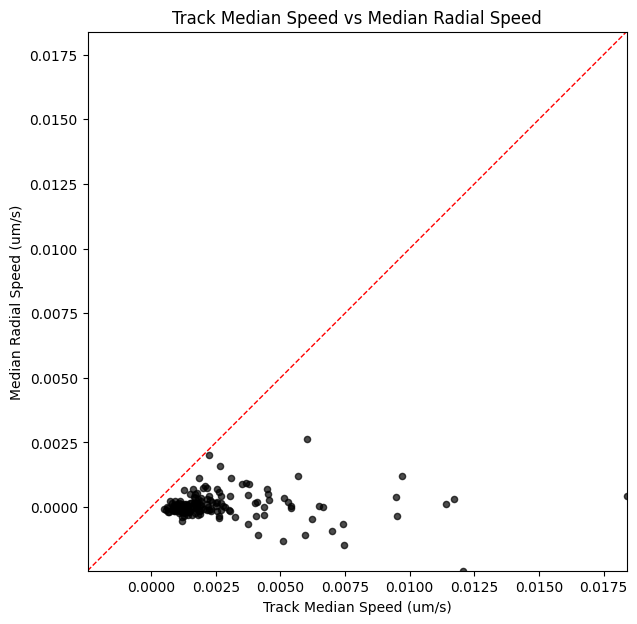

In [237]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    track_speed_comparison['track_median_speed_um_per_s'],
    track_speed_comparison['median_radial_speed_um_per_s'],
    s=20,
    c='black',
    alpha=0.7,
)

x = track_speed_comparison['track_median_speed_um_per_s'].to_numpy()
y = track_speed_comparison['median_radial_speed_um_per_s'].to_numpy()
slope, intercept = np.polyfit(x, y, 1)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = slope * x_fit + intercept

ax.plot(x_fit, y_fit, color='red', linestyle='--', linewidth=1)
ax.set_xlabel('Track Median Speed (um/s)')
ax.set_ylabel('Median Radial Speed (um/s)')
ax.set_title('Track Median Speed vs Median Radial Speed')
plt.show()


### Compare median radial speed with median tangential speed

This plot compares the median radial component of motion with the median tangential component for each track.


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    track_motion_summary['median_radial_speed_um_per_s'],
    track_motion_summary['median_tangential_speed_um_per_s'],
    s=20,
    c='black',
    alpha=0.7,
)
ax.set_xlabel('Median Radial Speed (um/s)')
ax.set_ylabel('Median Tangential Speed (um/s)')
ax.set_title('Median Radial Speed vs Median Tangential Speed')
plt.show()


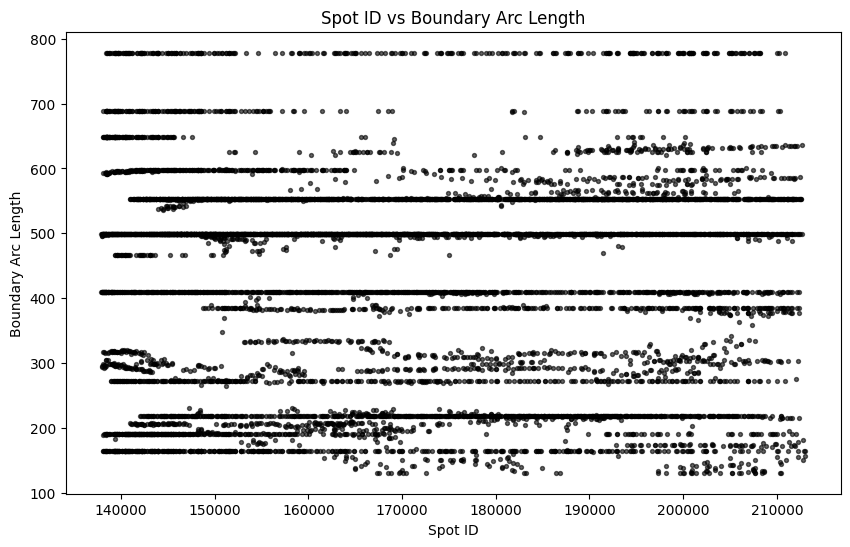

In [238]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_spots['Spot ID'], df_spots['boundary_arc_length'], s=8, c='black', alpha=0.6)
ax.set_xlabel('Spot ID')
ax.set_ylabel('Boundary Arc Length')
ax.set_title('Spot ID vs Boundary Arc Length')
plt.show()


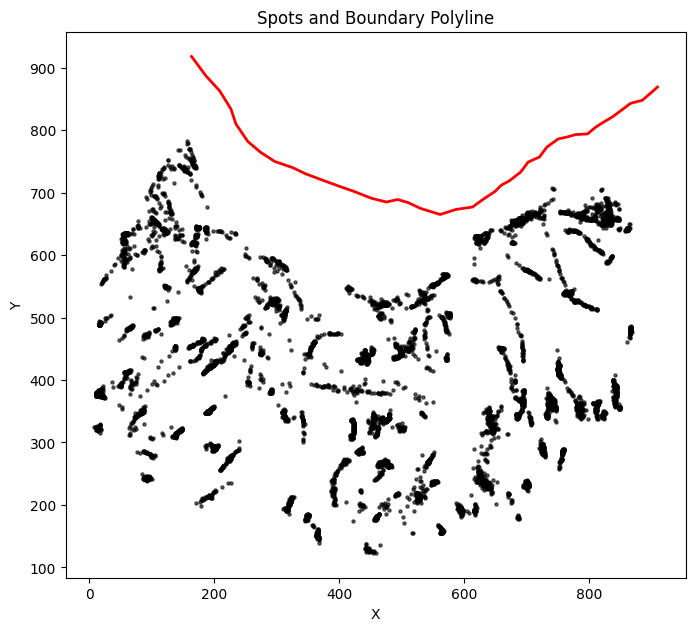

In [239]:
import matplotlib.pyplot as plt
import numpy as np

curve_plot = df.iloc[:, :2].dropna().to_numpy(dtype=float)
spot_xy_plot = df_spots.iloc[:, [4, 5]].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(spot_xy_plot[:, 0], spot_xy_plot[:, 1], s=5, c='black', alpha=0.6)
ax.plot(curve_plot[:, 0], curve_plot[:, 1], c='red', linewidth=2)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Spots and Boundary Polyline')
ax.set_aspect('equal', adjustable='box')
plt.show()


In [240]:
# From the plot we can see that the boundary created by hand follows the shape of the spots even if the assumed distance from the boundary is substantially greater than 0 for all points.